Question: Can UV-Vis absorption spectra be used to predict the concentrations of multiple chemical compounds in a mixture?
Data Source: https://zenodo.org/records/19324549?
Access date: 11-08-26

In [5]:

import pandas as pd

# Load the dataset
data = pd.read_csv("../data/Chemcial_Data_for_PLS.csv", encoding="utf-8-sig")

# Print the number of rows
print("Number of rows:", len(data))

# Print the column names
print("\nColumn names:")
print(data.columns.tolist())

# Print the number of columns
print("\nNumber of columns:", len(data.columns))

# Unit of measured variable
print("\nUnit of measured variable:")
print("UV-Vis absorbance: dimensionless (AU)")
print("Wavelength: nanometers (nm)")


Number of rows: 846

Column names:
['Volume', 'Bromide', 'Fluopyram', 'Diflufenican', 'Mesosulfuron', 'Port', 'Season', 'Soil', 'Storm', '200', '202.5', '205', '207.5', '210', '212.5', '215', '217.5', '220', '222.5', '225', '227.5', '230', '232.5', '235', '237.5', '240', '242.5', '245', '247.5', '250', '252.5', '255', '257.5', '260', '262.5', '265', '267.5', '270', '272.5', '275', '277.5', '280', '282.5', '285', '287.5', '290', '292.5', '295', '297.5', '300', '302.5', '305', '307.5', '310', '312.5', '315', '317.5', '320', '322.5', '325', '327.5', '330', '332.5', '335', '337.5', '340', '342.5', '345', '347.5', '350', '352.5', '355', '357.5', '360', '362.5', '365', '367.5', '370', '372.5', '375', '377.5', '380', '382.5', '385', '387.5', '390', '392.5', '395', '397.5', '400', '402.5', '405', '407.5', '410', '412.5', '415', '417.5', '420', '422.5', '425', '427.5', '430', '432.5', '435', '437.5', '440', '442.5', '445', '447.5', '450', '452.5', '455', '457.5', '460', '462.5', '465', '467.5',

## Imports

Loads the libraries used below. Nothing is printed.

In [6]:
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict

## Parameters

Every number that encodes a scientific choice is set here. Some of these are provisional and should be revisited after the exploration plots: the wavelength window, the number of held-out experiments, and the latent-variable tolerance. Expect no output.

In [7]:
DATA_PATH = "../data/Chemcial_Data_for_PLS.csv"  # file exactly as downloaded from Zenodo
TARGETS = ["Bromide", "Fluopyram", "Diflufenican", "Mesosulfuron"]  # compounds to predict; units not stated in the source
GROUP_COLUMNS = ["Season", "Soil", "Storm"]  # one combination = one experiment (12 in all); samples from one experiment are not independent
WAVELENGTH_MIN_NM = 200.0  # nm; shortest wavelength recorded; revisit after plotting the raw spectra
WAVELENGTH_MAX_NM = 737.5  # nm; longest wavelength with data, because the 740-750 nm columns are empty in every row
N_TEST_EXPERIMENTS = 3  # experiments held out for the final test, about 25% of the samples
MAX_LATENT_VARIABLES = 15  # largest number of PLS latent variables tried in cross-validation
LV_TOLERANCE = 0.05  # fraction; choose the fewest latent variables whose CV RMSE is within 5% of the minimum, to avoid fitting noise
RANDOM_SEED = 527  # seeds the choice of test experiments so the split is reproducible

rng = np.random.default_rng(RANDOM_SEED)

## Load and clean the data

Reads the file as downloaded, keeps the wavelengths inside the window, and drops any sample with a missing value inside it. The `utf-8-sig` encoding removes an invisible byte-order mark at the start of the first column name ("Volume"). Each sample is labelled with its experiment (season-soil-storm). Expect the number of samples dropped, the shape of the spectra matrix, and the absorbance range.

In [8]:
raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

wavelength_columns = [c for c in raw.columns if c.replace(".", "", 1).isdigit()]
wavelengths_all = np.array([float(c) for c in wavelength_columns])  # nm
in_window = (wavelengths_all >= WAVELENGTH_MIN_NM) & (wavelengths_all <= WAVELENGTH_MAX_NM)
spectral_columns = [c for c, keep in zip(wavelength_columns, in_window) if keep]
wavelengths = wavelengths_all[in_window]  # nm

complete = raw[spectral_columns + TARGETS].notna().all(axis=1)
print(f"Samples dropped for missing values in the window: {(~complete).sum()}")
data = raw.loc[complete].reset_index(drop=True).copy()
data["experiment"] = data[GROUP_COLUMNS].astype(str).agg("-".join, axis=1)

X = data[spectral_columns].to_numpy(dtype=float)  # absorbance, units not stated in the source
Y = data[TARGETS]  # concentrations, units not stated in the source
groups = data["experiment"].to_numpy()

print(f"Spectra matrix: {X.shape[0]} samples x {X.shape[1]} wavelengths ({wavelengths[0]:g}-{wavelengths[-1]:g} nm)")
print(f"Experiments: {data['experiment'].nunique()}")
print(f"Absorbance range: {X.min():.2f} to {X.max():.2f}")

Samples dropped for missing values in the window: 1
Spectra matrix: 845 samples x 216 wavelengths (200-737.5 nm)
Experiments: 12
Absorbance range: 1.26 to 106.70


**Check against the chemistry:** absorbance values near 100 are not absorbance in AU for a 1 cm cell. The values are probably normalized to path length (for example, absorbance per metre, as reported by in-situ UV-Vis probes). Confirm the units in the Zenodo record before interpreting magnitudes.

## Split the experiments into training and test sets

Holds out `N_TEST_EXPERIMENTS` whole experiments, chosen with the seeded generator, as the final test set; the remaining experiments are used for cross-validation and fitting. Whole experiments are held out, not random samples, because samples from the same season-soil-storm are not independent, and a random split would let the model see the test storms during training. Expect the names of the test experiments and the number of samples on each side.

In [9]:
experiment_names = np.sort(data["experiment"].unique())
test_experiments = rng.choice(experiment_names, size=N_TEST_EXPERIMENTS, replace=False)

is_test = data["experiment"].isin(test_experiments).to_numpy()
is_train = ~is_test

X_train, X_test = X[is_train], X[is_test]  # absorbance
groups_train = groups[is_train]

print(f"Test experiments: {sorted(test_experiments)}")
print(f"Training samples: {is_train.sum()} from {len(np.unique(groups_train))} experiments")
print(f"Test samples: {is_test.sum()} ({is_test.mean():.0%} of all samples)")

Test experiments: ['Summer-Sand-s2', 'Summer-Sand-s3', 'Winter-Sand-s1']
Training samples: 621 from 9 experiments
Test samples: 224 (27% of all samples)


## Choose the number of latent variables by cross-validation

For each compound, fits PLS models with 1 to `MAX_LATENT_VARIABLES` latent variables on the training experiments. Each model is scored by leave-one-experiment-out cross-validation. `scale=False` mean-centers the spectra without dividing each wavelength by its standard deviation, because scaling would inflate noisy, low-signal wavelengths to the same weight as real absorption bands. The chosen number is the fewest latent variables within `LV_TOLERANCE` of the lowest CV error. Expect a table of the chosen numbers.

In [10]:
logo = LeaveOneGroupOut()
lv_range = np.arange(1, MAX_LATENT_VARIABLES + 1)
cv_rmse = pd.DataFrame(index=lv_range, columns=TARGETS, dtype=float)  # concentration units

for target in TARGETS:
    y_train = Y.loc[is_train, target].to_numpy()
    for n_lv in lv_range:
        model = PLSRegression(n_components=n_lv, scale=False)
        y_cv = cross_val_predict(model, X_train, y_train, groups=groups_train, cv=logo).ravel()
        cv_rmse.loc[n_lv, target] = root_mean_squared_error(y_train, y_cv)

best_lv = {}
for target in TARGETS:
    threshold = (1 + LV_TOLERANCE) * cv_rmse[target].min()
    best_lv[target] = int(cv_rmse.index[cv_rmse[target] <= threshold][0])

print(pd.Series(best_lv, name="latent variables chosen"))

Bromide         4
Fluopyram       4
Diflufenican    1
Mesosulfuron    1
Name: latent variables chosen, dtype: int64


## Plot the cross-validation curves

Plots CV error against the number of latent variables for each compound, with the chosen number marked by a dotted line. Expect the error to drop and then level off; a curve that never drops means the spectra carry little information about that compound.

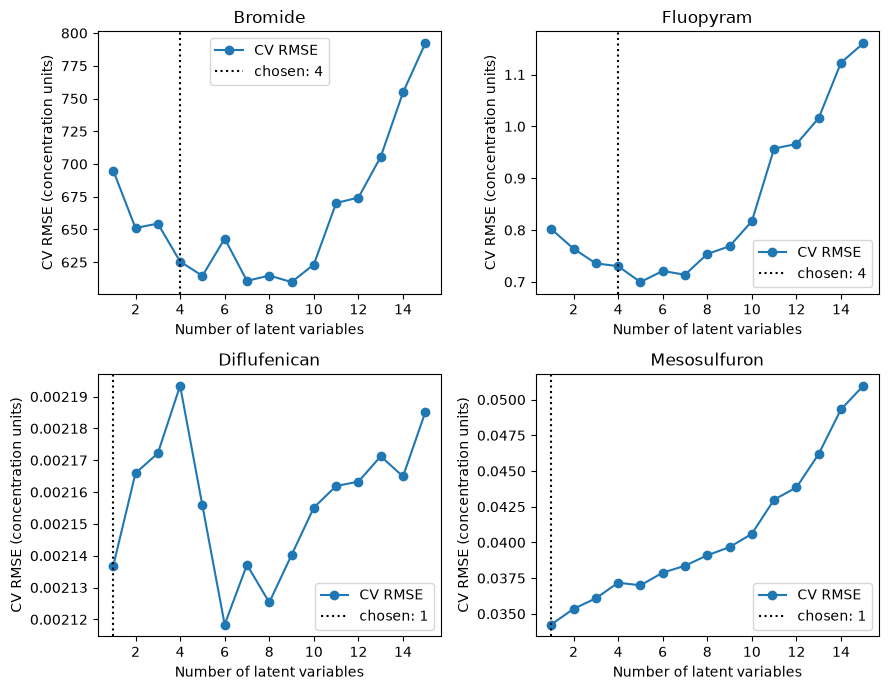

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, target in zip(axes.flat, TARGETS):
    ax.plot(lv_range, cv_rmse[target], marker="o", linestyle="-", label="CV RMSE")
    ax.axvline(best_lv[target], color="black", linestyle=":", label=f"chosen: {best_lv[target]}")
    ax.set_title(target)
    ax.set_xlabel("Number of latent variables")
    ax.set_ylabel("CV RMSE (concentration units)")
    ax.legend()
fig.tight_layout()
plt.show()

The plot shows how the number of latent variables affects PLS prediction error for each chemical, with the lowest cross-validation RMSE identifying the best number of latent variables.

## Fit the final models and score them on the test experiments

Refits each compound's model on all training experiments with its chosen number of latent variables, then predicts the held-out experiments. Reported for each compound:

- **RMSEP**: root-mean-square error of prediction on the test set, in concentration units.
- **R²**: fraction of the test-set variance explained.
- **RPD**: standard deviation of the test reference values divided by RMSEP. Below about 1.5 is not useful; about 2 or higher is usable.
- **Baseline RMSE**: the error from always predicting the training mean. PLS has to beat this clearly.

Expect a table with one row per compound.

In [12]:
results = []
test_predictions = {}
coefficients = {}

for target in TARGETS:
    y_train = Y.loc[is_train, target].to_numpy()
    y_test = Y.loc[is_test, target].to_numpy()

    model = PLSRegression(n_components=best_lv[target], scale=False).fit(X_train, y_train)
    y_pred = model.predict(X_test).ravel()
    rmsep = root_mean_squared_error(y_test, y_pred)
    baseline_rmse = root_mean_squared_error(y_test, np.full_like(y_test, y_train.mean()))

    test_predictions[target] = (y_test, y_pred)
    coefficients[target] = model.coef_.ravel()
    results.append({
        "compound": target,
        "latent variables": best_lv[target],
        "RMSEP": rmsep,
        "baseline RMSE": baseline_rmse,
        "R2": r2_score(y_test, y_pred),
        "RPD": y_test.std(ddof=1) / rmsep,
    })

results_table = pd.DataFrame(results).set_index("compound")
print(results_table.to_string(float_format=lambda v: f"{v:.4g}"))

              latent variables    RMSEP  baseline RMSE       R2    RPD
compound                                                              
Bromide                      4    658.2            883   0.4271  1.324
Fluopyram                    4    1.118          1.411   0.2924  1.191
Diflufenican                 1 0.001283        0.00126 -0.03906 0.9832
Mesosulfuron                 1  0.03624         0.0369 -0.05084 0.9777


## Predicted vs. measured concentrations

Plots each test sample's predicted concentration against its measured concentration, with a dashed 1:1 line. Points on the line are perfect predictions. Expect the scatter around the line to be tight for a compound the spectra can predict.

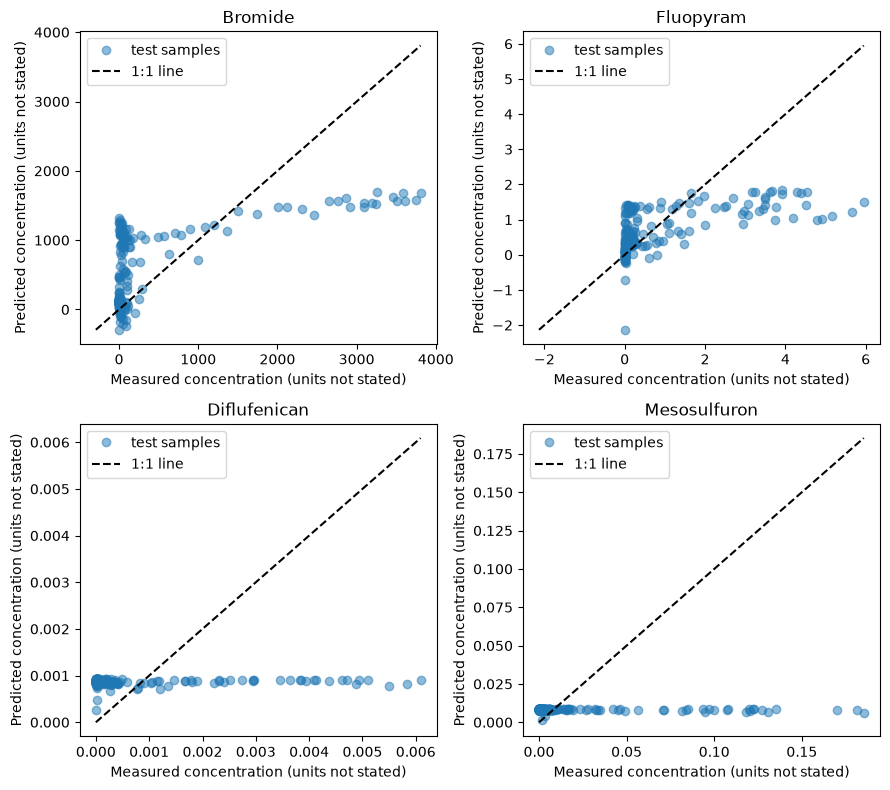

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, target in zip(axes.flat, TARGETS):
    y_test, y_pred = test_predictions[target]
    limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(y_test, y_pred, marker="o", linestyle="none", alpha=0.5, label="test samples")
    ax.plot(limits, limits, color="black", linestyle="--", label="1:1 line")
    ax.set_title(target)
    ax.set_xlabel("Measured concentration (units not stated)")
    ax.set_ylabel("Predicted concentration (units not stated)")
    ax.legend()
fig.tight_layout()
plt.show()

The plot compares measured and PLS-predicted concentrations for each chemical, where points closer to the dashed 1:1 line indicate more accurate predictions.

## Residuals

Plots each test sample's residual (measured minus predicted) against its predicted concentration. Expect residuals scattered evenly around zero. A curve suggests the relationship is not linear, and a funnel shape suggests the error grows with concentration.

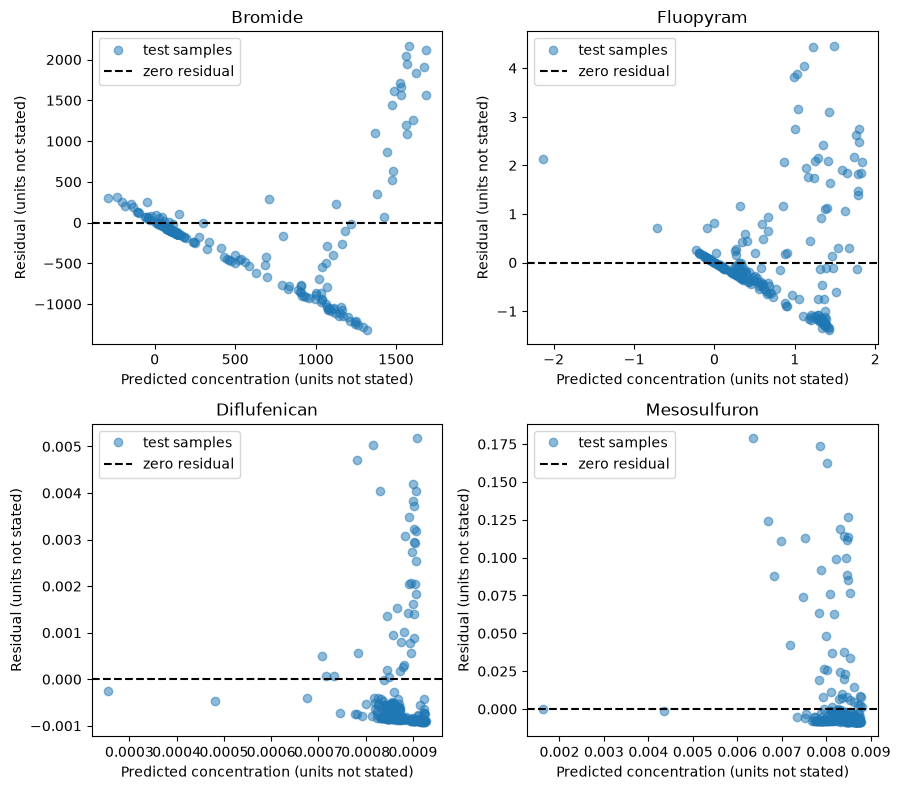

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, target in zip(axes.flat, TARGETS):
    y_test, y_pred = test_predictions[target]
    ax.plot(y_pred, y_test - y_pred, marker="o", linestyle="none", alpha=0.5, label="test samples")
    ax.axhline(0, color="black", linestyle="--", label="zero residual")
    ax.set_title(target)
    ax.set_xlabel("Predicted concentration (units not stated)")
    ax.set_ylabel("Residual (units not stated)")
    ax.legend()
fig.tight_layout()
plt.show()

The plot shows the prediction errors (residuals) for each chemical, helping identify systematic bias, patterns, or unusually large errors in the PLS model.

## Which wavelengths drive each prediction

Plots each model's regression coefficients against wavelength. Large positive or negative coefficients mark the wavelengths the model relies on. Expect bromide to rely on wavelengths below about 230 nm, where bromide absorbs, and the pesticides on their aromatic bands around 250-300 nm. A model that relies mostly on other regions may be predicting from something that correlates with the compound rather than from the compound's own absorbance.

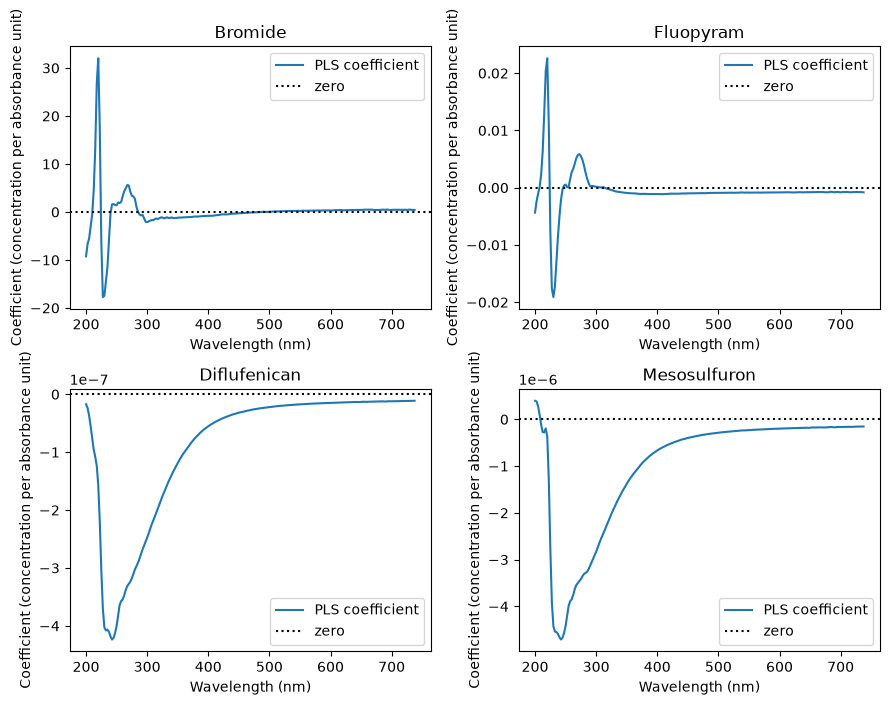

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, target in zip(axes.flat, TARGETS):
    ax.plot(wavelengths, coefficients[target], linestyle="-", label="PLS coefficient")
    ax.axhline(0, color="black", linestyle=":", label="zero")
    ax.set_title(target)
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Coefficient (concentration per absorbance unit)")
    ax.legend()
fig.tight_layout()
plt.show()

The plot shows how each wavelength contributes to the PLS-predicted concentration of each chemical, with positive and negative coefficients indicating the direction and strength of their influence.

**What my data cannot answer**:
The dataset contains 846 observations, with 221 UV-Vis absorbance measurements per sample and four concentration variables: Bromide, Fluopyram, Diflufenican, and Mesosulfuron. However, the concentration units are not stated in the information I have available, which limits the interpretation of the prediction errors. The dataset also cannot establish whether the model will perform equally well on samples from completely new storms unless it is tested on independent storm groups. Therefore, the data can be used to investigate whether spectra predict the four concentrations, but the reliability and generalizability of those predictions still need to be evaluated.

**Exploration**: My initial exploration and curve-fitting analysis showed that using one wavelength to predict each chemical concentration was not sufficiently accurate. Bromide had an R² of 0.2701, while Fluopyram, Diflufenican, and Mesosulfuron had negative R² values. This changed my analysis plan from using individual wavelength curve-fitting models to using PLS regression. PLS allows multiple wavelengths to contribute to the prediction and accounts for the strong correlations between neighboring wavelengths.

My first analysis uses PLS regression to predict the concentrations of all four chemicals from their UV-Vis spectra. An important assumption to check is that the model can predict concentrations for samples from new storms rather than simply learning patterns specific to storms in the training data. I will check this by using grouped cross-validation, keeping samples from the same storm together, and evaluating the model on held-out storm groups. I will also compare its prediction error against a baseline model that always predicts the training-set mean.

My next step is to investigate why PLS performed poorly for Diflufenican and Mesosulfuron and whether the results are affected by the limited number of experiment groups. I will inspect the residual plots, regression coefficients, and concentration distributions to identify possible sources of error. I will also verify the concentration and absorbance units from the dataset documentation. This step will be complete when I can explain the limitations of the current predictions and determine whether additional preprocessing, more representative samples, or a different analytical approach is needed.

## Software versions

Prints the Python and package versions used to run this notebook.

In [16]:
print(f"Python       {sys.version.split()[0]}")
print(f"NumPy        {np.__version__}")
print(f"pandas       {pd.__version__}")
print(f"Matplotlib   {matplotlib.__version__}")
print(f"scikit-learn {sklearn.__version__}")

Python       3.14.8
NumPy        2.5.3
pandas       3.0.6
Matplotlib   3.11.2
scikit-learn 1.9.1
